# Nouvelles mutations (newmut) : essai à la main et marches aléatoires

Les nouvelles mutations d'`evomol/newmut` (voir `evomol/newmut/README.md`) :
- **règles R1 à R5**, lues sur la matrice des ordres de liaison : une mutation n'est proposée que si la molécule
  produite ne crée aucune nouvelle violation (valence, deux carbones `s` liés, deux doubles liaisons sur un carbone,
  cycles pontés ou grands cycles non plans, carbone `s` portant 4 atomes lourds) ;
- **nouvelles mutations** : `AppendAtomRuleMG` (ajout d'atome, un C sur un carbone `s` par une double liaison),
  `SubstituteShiftMG` (substitution qui déplace les doubles liaisons), `GraftFragmentMG` (greffe d'un fragment),
  `AnnelateMG` (fusion d'un cycle sur une liaison), `FlipAlternatingPathMG` (bascule quinoïde le long d'un chemin
  alterné), `AromatizeMG` (structure de Kekulé d'un système de cycles).

Première partie : essayer soi-même les mutations sur une molécule et les voir. Deuxième partie : marches aléatoires
comme dans `pi_walk.ipynb` (mêmes fichiers, mêmes figures), avec ces mutations. Le code est dans
`scripts/newmut/newmut_walk.py`.

In [13]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
sys.path.insert(0, str(ROOT / "scripts" / "newmut"))

import matplotlib.pyplot as plt
from IPython.display import display

import newmut_walk as nw                     # scripts/newmut/newmut_walk.py (se place à la racine du projet)

## Configuration

Mêmes réglages que `pi_walk.ipynb`, plus ceux des nouvelles mutations (fin de la liste). La configuration sert aux
deux parties : `nw.configure(CONFIG)` règle l'espace d'action utilisé par les essais à la main.

In [14]:
LABEL = "test"         # nom de l'expérience : dossier results/newmut_walk/<LABEL>/
CONFIG = nw.make_config(
    # ── départ et marche
    START="c1ccccc1",              # SMILES d'où part le burn-in
    SEED=1,                        # marche k : burn-in SEED + 2k, marche SEED + 2k + 1 ; None : au hasard
    BURN_IN_STEPS=0,            # pas pour obtenir un départ aléatoire (0 : la marche part de START)
    N_STEPS=2000,                   # pas de la marche observée
    MAX_ATOMS=1000,                # nb max d'atomes lourds
    ACCEPTED_ATOMS=["C", "O", "N"],

    COUNT_VALID_NEIGHBORS=False,   # True : valider tout le voisinage à chaque pas
    EXCLUDE_CURRENT=True,          # la molécule courante n'est jamais son propre voisin
    ACTION_TYPES= ["AppendAtomRuleMG","RemoveAtomMG", "ChangeBondMG", "SubstituteShiftMG", "AromatizeMG"],             # None : toutes les mutations de l'espace d'action ; sinon une liste de noms,
    #   ex. ["AppendAtomRuleMG", "AromatizeMG"] (noms affichés par la cellule suivante)
    SUBSTITUTION_NO_SHIFT=True,    # SubstituteShiftMG sans abaisser ni déplacer de double liaison
    UNIFORM_ACTION_TYPE=True,      # tirer d'abord le type de mutation, puis un voisin de ce type
    R2_HETERO=False,               # R2 aussi pour N–N, N–O, O–O (deux atomes sans liaison multiple)
    R2_HETERO_OUTSIDE_RINGS=False, # avec R2_HETERO : ces liaisons refusées seulement hors cycle
    # ── espace d'action d'evomol (comme pi_walk)
    INSERT_CARBON=True,            # InsertCarbonMG
    AVOID_BOND_BREAKING=False,     # ChangeBondMG ne supprime jamais de liaison
    AVOID_BOND_FORMING=False,      # ChangeBondMG ne crée jamais de liaison
    BOND_CHANGE_BY_ONE=True,       # ChangeBondMG d'un cran à la fois (0→1, 1→2…)
    WITH_ADD_GROUP=False,          # AddGroupMG
    WITH_REMOVE_GROUP=False,       # RemoveGroupMG
    # ── filtres : tous désactivés
    FILTER_HUCKEL=False, MAX_SP3=None, FILTER_REALISM=None, FILTER_HETERO=False, MAX_RING_N=None,
    # ── nouvelles mutations (evomol/newmut)
    MATRIX_RULES=True,             # les mutations d'evomol respectent les règles R1-R5
    APPEND_ATOM_RULE=True,         # AppendAtomRuleMG remplace AddAtomMG
    SUBSTITUTION_SHIFT=True,       # SubstituteShiftMG remplace SubstituteAtomMG
    GRAFT=True,                    # GraftFragmentMG
    ANNELATE=True,                 # AnnelateMG
    FLIP_PATH=True,                # FlipAlternatingPathMG
    AROMATIZE=True,                # AromatizeMG
    GRAFT_FRAGMENTS=None,          # None : vocabulaire par défaut ; ou {"nom": "SMILES avec [*:1]", …}
    ANNELATION_FRAGMENTS=None,     # None : vocabulaire par défaut ; ou {"nom": "[*:1]…[*:2]", …}
)
N_WALKS = 20                        # marches (graines 0 … N_WALKS − 1)
N_JOBS = 5                      # processus en parallèle (None : nb de cœurs − 1)
OUT_DIR = f"notebooks/random_walk/results/newmut_walk/{LABEL}"  # relatif à la racine du projet
FIGURES = Path(OUT_DIR) / "figures"

In [15]:
nw.configure(CONFIG)
print("mutations de l'espace d'action :")
for action in nw.MolecularGraph.action_space:
    print("  ", action.class_name())

mutations de l'espace d'action :
   AppendAtomRuleMG
   ChangeBondMG
   CutAtomMG
   InsertCarbonMG
   MoveGroupMG
   RemoveAtomMG
   SubstituteShiftMG
   GraftFragmentMG
   AnnelateMG
   FlipAlternatingPathMG
   AromatizeMG


## Essayer les mutations à la main

Choisir une molécule (`SMILES`) : dessin avec les numéros d'atomes, sa matrice (électrons de valence sur la
diagonale, ordres de liaison ailleurs ; H implicites, étiquette des carbones `s` / `a` / `d` / `t` et hybridation) et
les règles qu'elle ne respecte pas (tableau vide : aucune).

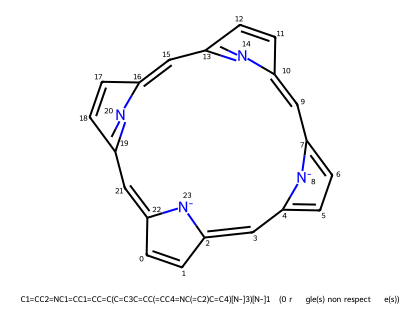

,C0,C1,C2,C3,C4,C5,C6,C7,N8,C9,...,C17,C18,C19,N20,C21,C22,N23,H,étiquette,hybridation
C0,4,2,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,1,a,sp2
C1,2,4,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,a,sp2
C2,0,1,4,2,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,a,sp2
C3,0,0,2,4,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,a,sp2
C4,0,0,0,1,4,2,0,0,1,0,...,0,0,0,0,0,0,0,0,a,sp2
C5,0,0,0,0,2,4,1,0,0,0,...,0,0,0,0,0,0,0,1,a,sp2
C6,0,0,0,0,0,1,4,2,0,0,...,0,0,0,0,0,0,0,1,a,sp2
C7,0,0,0,0,0,0,2,4,1,1,...,0,0,0,0,0,0,0,0,a,sp2
N8,0,0,0,0,1,0,0,1,5,0,...,0,0,0,0,0,0,0,1,,sp2
C9,0,0,0,0,0,0,0,1,0,4,...,0,0,0,0,0,0,0,1,a,sp2


,règle,atomes,message


In [37]:
SMILES = "C1=CC2=CC3=CC=C([N-]3)C=C4C=CC(=N4)C=C5C=CC(=N5)C=C1[N-]2"  
display(nw.show_molecule(SMILES))
display(nw.matrix_table(SMILES))
display(nw.violations_table(SMILES))

### Mutations possibles, par type

`candidates` : mutations que le type sait faire sur cette molécule ; `permises` : celles qui respectent les règles
(les seules que l'algorithme peut tirer) ; `refusées` : celles que les règles écartent.

In [43]:
display(nw.mutation_summary(SMILES))

,candidates,permises,refusées,molécules différentes
mutation,,,,
AppendAtomRuleMG,36,36,0,21
ChangeBondMG,90,12,78,10
CutAtomMG,14,0,14,0
InsertCarbonMG,39,8,31,6
MoveGroupMG,0,0,0,0
RemoveAtomMG,0,0,0,0
SubstituteShiftMG,14,14,0,8
GraftFragmentMG,84,84,0,49
AnnelateMG,4,4,0,2


### Voir toutes les mutations d'un type

Tableau puis dessins. Les numéros d'atomes sont ceux de la molécule de départ (les atomes ajoutés prennent les
numéros suivants). Atomes modifiés en **vert** si la mutation est permise, en **rouge** si les règles la refusent
(la règle est dans la légende, ex. « R2 +1 » : une paire de carbones `s` liés en plus).

,n°,mutation,résultat,permise,raison
0,0,inversion du chemin C0–C22–C21–C19–N20–C16–C15...,C1=C=c2cc3ccc(cc4nc(cc5nc(cc=1[n-]2)C=C5)C=C4)...,False,R3 +2
1,1,inversion du chemin C0–C22–C21–C19–N20–C16–C15...,C1=CC2=C=c3ccc([n-]3)=CC3=NC(=CC4=NC(=CC=1[N-]...,False,R3 +2
2,2,inversion du chemin C0–C22–C21–C19–N20–C16–C15...,C1=Cc2cc3[n-]c(cc4nc(cc5nc(cc=1[n-]2)C=C5)C=C4...,False,R3 +2
3,3,inversion du chemin C1–C2–C3–C4–C5–C6,C1=Cc2cc3[n-]c(cc4nc(cc5nc(cc=1[n-]2)C=C5)C=C4...,False,R3 +2
4,4,inversion du chemin C1–C2–C3–C4–C5–C6–C7–C9,C1=CC2=CC3=NC(=CC4=NC(=C=c5ccc([n-]5)=CC=1[N-]...,False,R3 +2
5,5,inversion du chemin C1–C2–C3–C4–C5–C6–C7–C9–C1...,C1=Cc2cc3nc(cc4[n-]c(cc5ccc(cc=1n2)[n-]5)=C=C4...,False,R3 +2
6,6,inversion du chemin C1–C2–C3–C4–C5–C6–C7–C9–C1...,C1=Cc2cc3ccc(cc4[n-]c(cc5nc(cc=1n2)C=C5)C=C=4)...,False,R3 +2
7,7,inversion du chemin C1–C2–C3–C4–C5–C6–C7–C9–C1...,C1=C2C=CC(=N2)C=C2C=C=C(C=c3ccc([n-]3)=CC3=NC=...,False,R3 +2
8,8,inversion du chemin C1–C2–C3–C4–C5–C6–C7–C9–C1...,C1=Cc2cc3[n-]c(cc4ccc(cc5nc(cc=1n2)C=C5)[n-]4)...,False,R3 +2
9,9,inversion du chemin C1–C2–C3–C4–C5–C6–C7–C9–C1...,C1=Cc2cc3nc(cc4ccc(cc5[n-]c(cc=1n2)C=C=5)[n-]4...,False,R3 +2


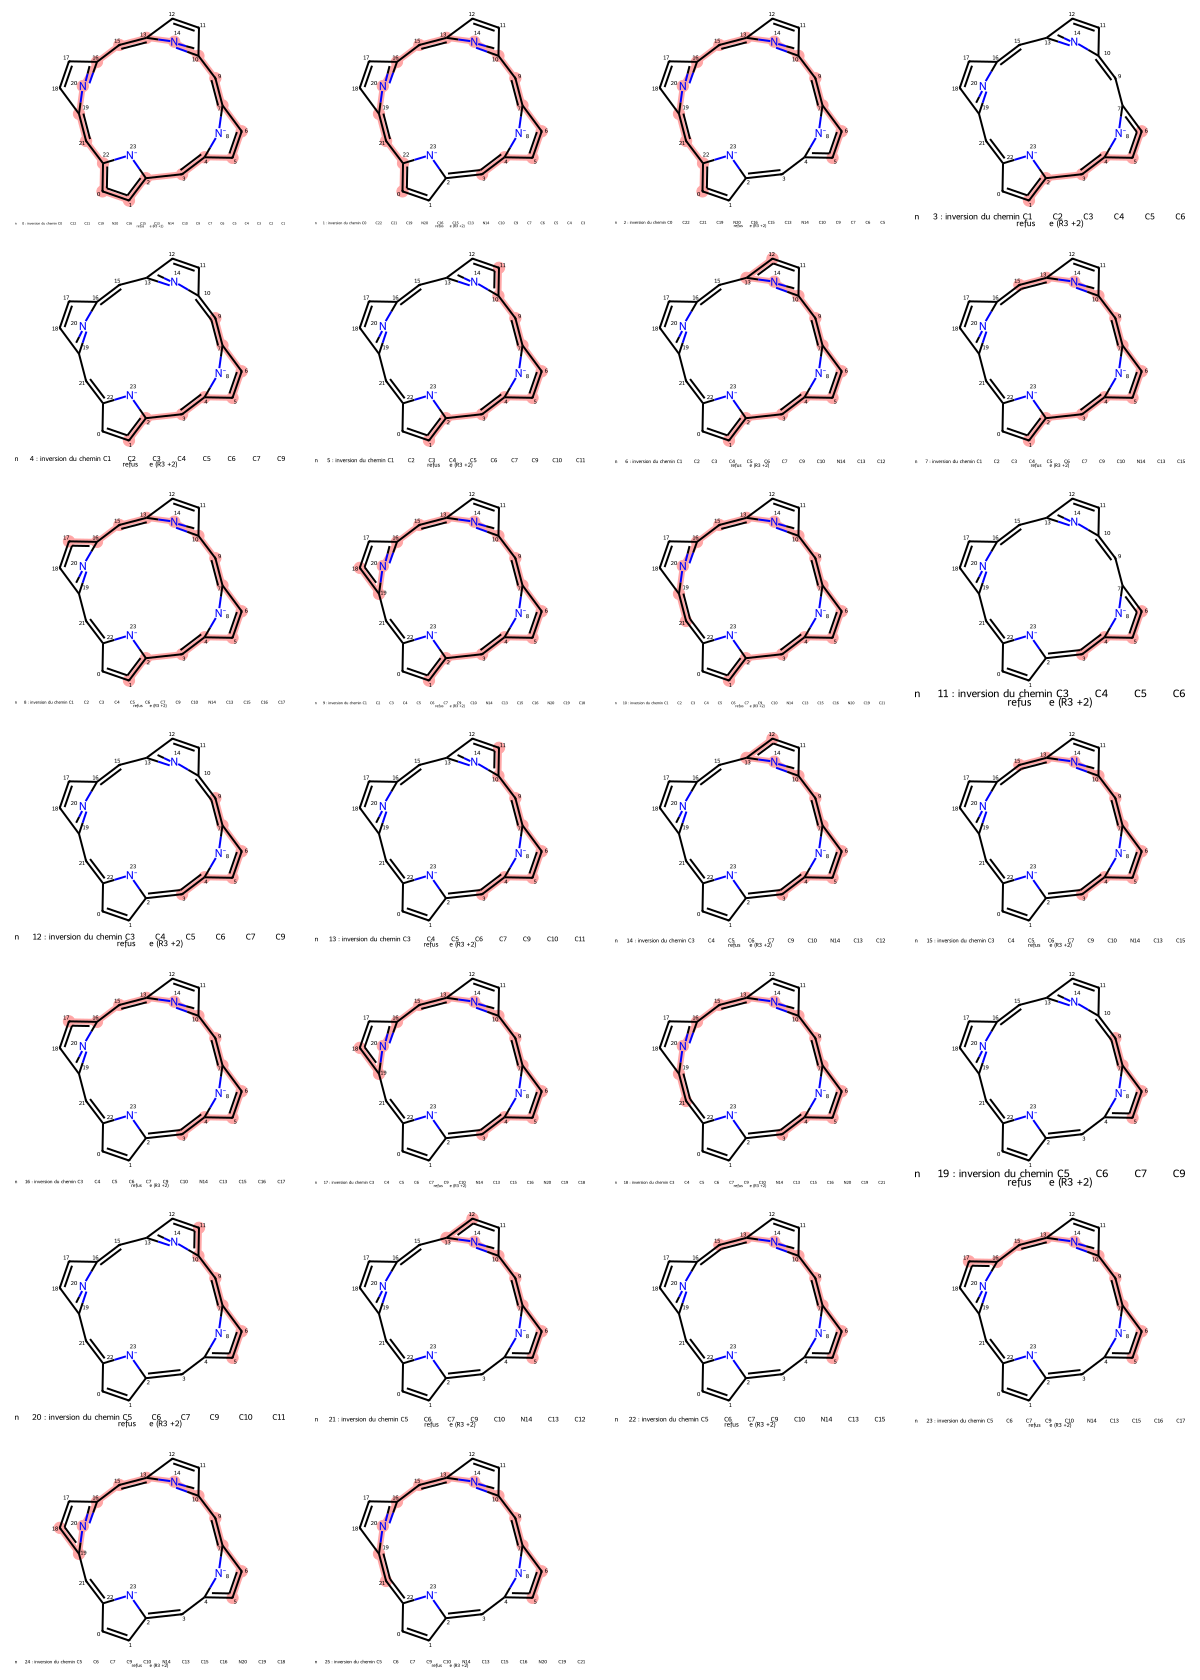

In [46]:
TYPE = "FlipAlternatingPathMG"     # un nom de la liste ci-dessus

display(nw.mutation_table(SMILES, TYPE))
nw.show_mutations(SMILES, TYPE, only_allowed=False)

### Appliquer une mutation

Le n° est celui du tableau. On voit le nom de l'opération (greffe, annélation, inversion…, comme dans l'atelier de
mutations), avant / après avec les atomes modifiés, les cases de la matrice qui changent et les règles. Une mutation
refusée par les règles est appliquée quand même, avec un avertissement, pour la voir.

La cellule met la nouvelle molécule dans `SMILES` : relancer les cellules précédentes (dessin, tableau) avant de
choisir le n° suivant, car ses atomes sont renumérotés. Relancer cette cellule seule appliquerait le même n° à la
nouvelle molécule, donc une autre mutation.

N0 → C
  opération : Substitution N → C sur l'atome 0 (cycle aromatique)
  élément N0 → C0
  règles : aucune nouvelle violation


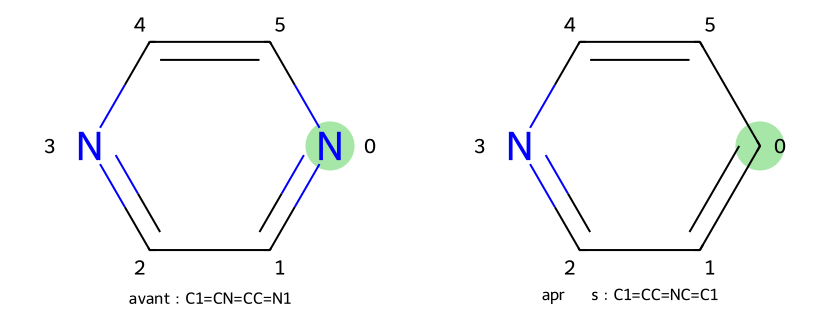

'C1=CC=NC=C1'

In [19]:
NUMBER = 0

SMILES = nw.apply_mutation(SMILES, TYPE, NUMBER)
SMILES

### Exemples de chaque nouvelle mutation

Une molécule typique par mutation (C, O, N seulement), mutations permises seulement.

SubstituteShiftMG sur C=Cc1ccccc1


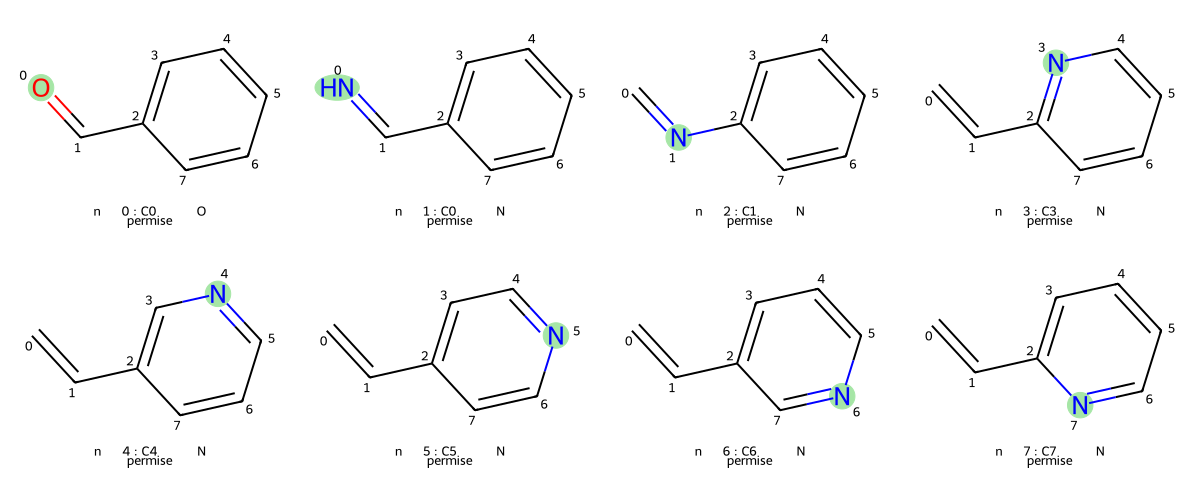

FlipAlternatingPathMG sur CC1=CC=C(C)O1


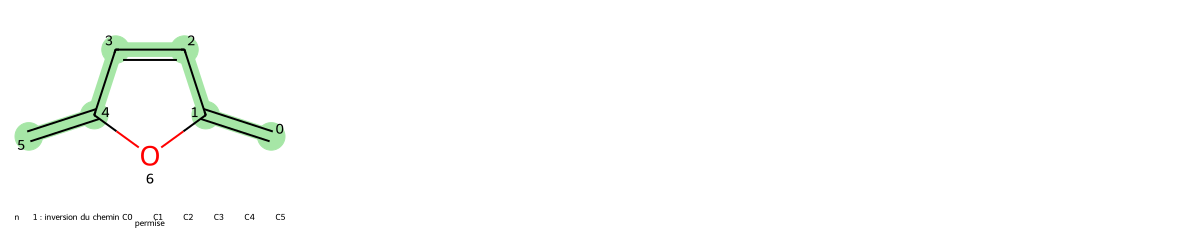

AromatizeMG sur C1=CNC=CC1


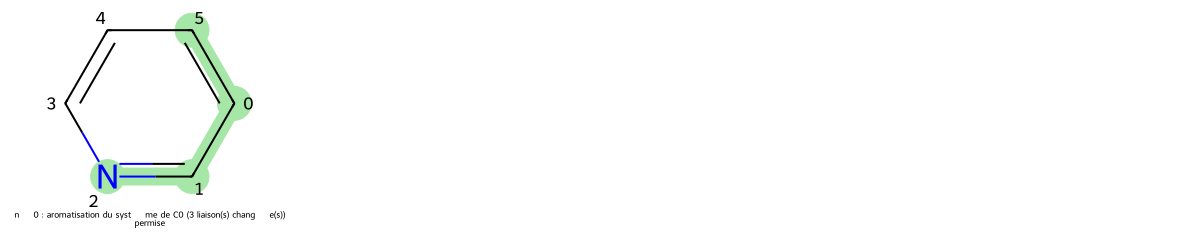

GraftFragmentMG sur c1ccncc1
35 mutations : seules les 12 premières sont dessinées (max_images)


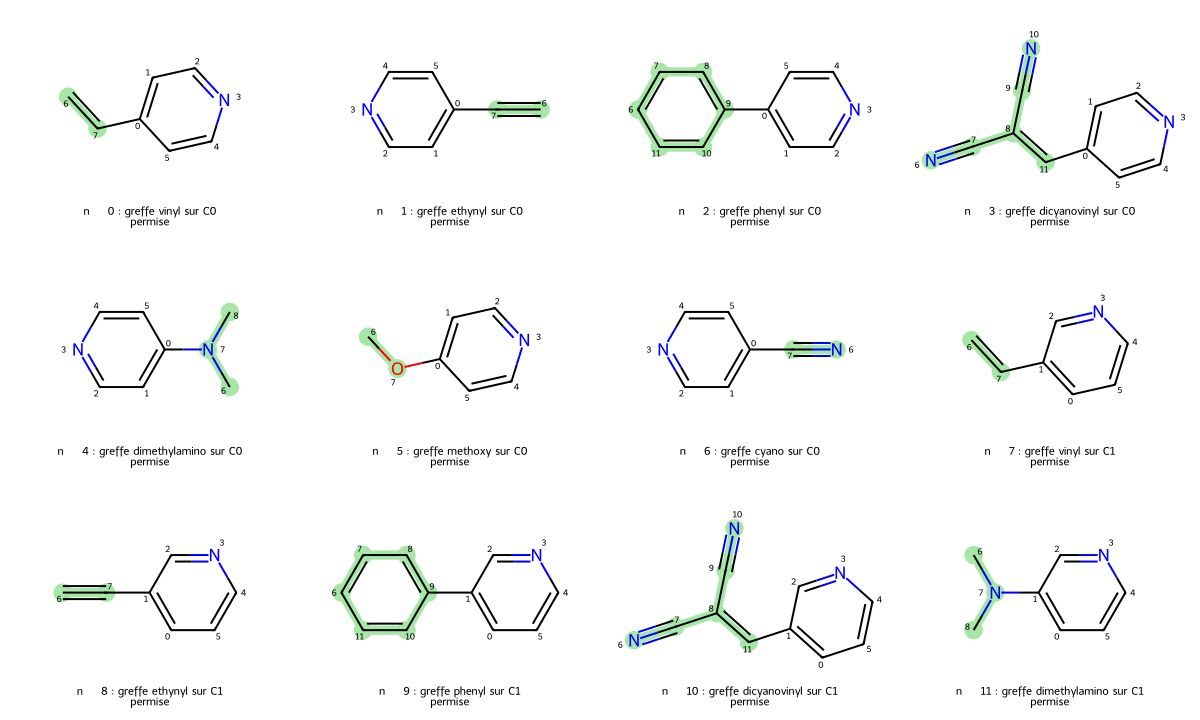

AnnelateMG sur c1cc[nH]c1


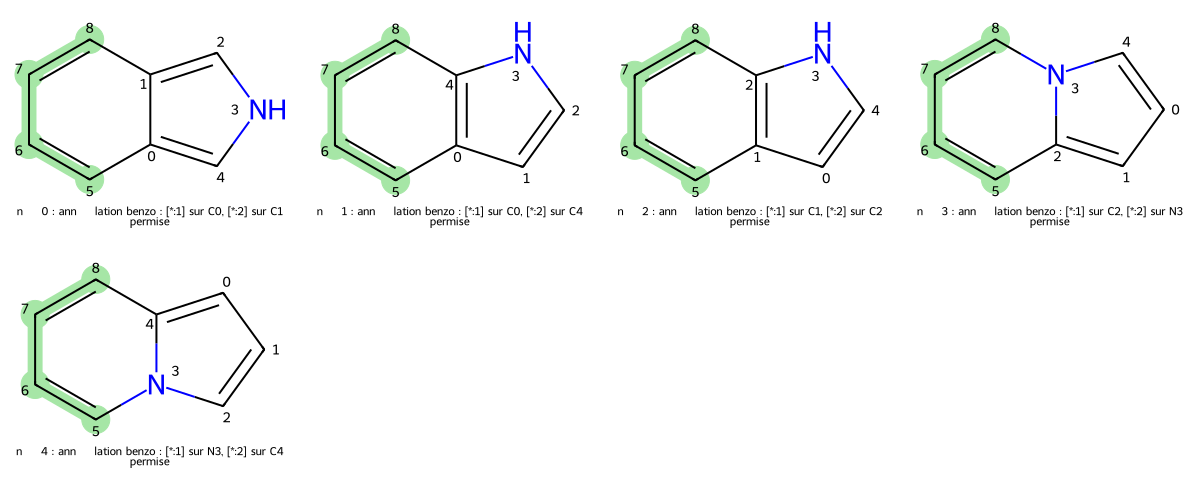

In [20]:
EXAMPLES = [
    ("C=Cc1ccccc1", "SubstituteShiftMG"),      # =CH2 → O : benzaldéhyde ; C du cycle → O : 2H-pyrane
    ("CC1=CC=C(C)O1", "FlipAlternatingPathMG"), # bascule quinoïde du 2,5-diméthylfurane
    ("C1=CNC=CC1", "AromatizeMG"),             # 1,4-dihydropyridine → pyridine
    ("c1ccncc1", "GraftFragmentMG"),           # greffes sur la pyridine
    ("c1cc[nH]c1", "AnnelateMG"),              # benzo sur le pyrrole : indole, isoindole
]
for smiles, action_type in EXAMPLES:
    print(f"{action_type} sur {smiles}")
    display(nw.show_mutations(smiles, action_type, only_allowed=True, max_images=12))

### Tirage au hasard, comme l'algorithme

Plusieurs mutations à la suite : à chaque fois un type de mutation au hasard, puis une mutation permise de ce type au
hasard (comme `NewMutNeighborhoodStrategy`). `lazy_rules=True` : les mutations sont essayées une par une jusqu'à la
première permise (même tirage, plus rapide).

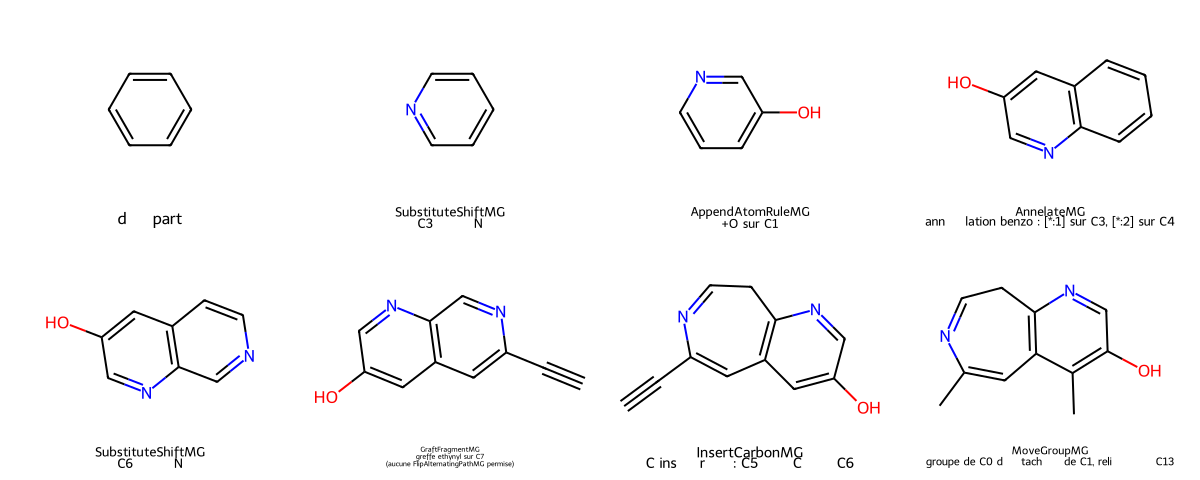

'CC1=CC2=C(CC=N1)N=CC(O)=C2C'

In [9]:
nw.random_mutations("c1ccccc1", n_mutations=8, lazy_rules=False, seed=0)

## Marches aléatoires

Comme `pi_walk.ipynb` : à chaque pas, la marche va vers un voisin tiré au hasard parmi tous les voisins (ici, les
voisins permis par les règles) ; on suit `n_atoms`, les systèmes π et Hückel. Les marches tournent en parallèle ;
relancer avec le même `LABEL` écrase les marches de ce dossier. Chaque pas liste et vérifie tout le voisinage :
compter environ 0,5 s par pas (2 marches de 200 pas : 2,5 min, mesuré le 2026-10-12).

In [22]:
#nw.run_walks(CONFIG, N_WALKS, OUT_DIR, N_JOBS)
walks = nw.load_walks(OUT_DIR)
for k, meta in nw.load_meta(OUT_DIR).items():
    print(f"marche {k} : départ {meta['walk_start']}  ({meta['t_total']:.0f} s)")
print("mutations :", ", ".join(meta["actions"]))

marche 0 : départ C1=CC=CC=C1  (177 s)
marche 10 : départ C1=CC=CC=C1  (225 s)
marche 11 : départ C1=CC=CC=C1  (91 s)
marche 12 : départ C1=CC=CC=C1  (972 s)
marche 13 : départ C1=CC=CC=C1  (74 s)
marche 14 : départ C1=CC=CC=C1  (224 s)
marche 15 : départ C1=CC=CC=C1  (94 s)
marche 16 : départ C1=CC=CC=C1  (478 s)
marche 17 : départ C1=CC=CC=C1  (135 s)
marche 18 : départ C1=CC=CC=C1  (151 s)
marche 19 : départ C1=CC=CC=C1  (187 s)
marche 1 : départ C1=CC=CC=C1  (540 s)
marche 2 : départ C1=CC=CC=C1  (260 s)
marche 3 : départ C1=CC=CC=C1  (236 s)
marche 4 : départ C1=CC=CC=C1  (79 s)
marche 5 : départ C1=CC=CC=C1  (111 s)
marche 6 : départ C1=CC=CC=C1  (2773 s)
marche 7 : départ C1=CC=CC=C1  (110 s)
marche 9 : départ C1=CC=CC=C1  (38 s)
mutations : AppendAtomRuleMG, RemoveAtomMG, ChangeBondMG, SubstituteShiftMG, AromatizeMG


## Mutations réalisées

Nombre de fois où chaque mutation a été faite, par marche puis au total ; « restart » : retour au départ faute de
voisin.

In [23]:
actions = next(iter(nw.load_meta(OUT_DIR).values()))["actions"]
display(nw.mutation_counts(walks, actions))

,marche 0,marche 1,marche 2,marche 3,marche 4,marche 5,marche 6,marche 7,marche 9,marche 10,...,marche 12,marche 13,marche 14,marche 15,marche 16,marche 17,marche 18,marche 19,total,%
action,,,,,,,,,,,,,,,,,,,,,
SubstituteShiftMG,494,496,487,475,517,483,501,455,509,477,...,471,512,471,488,493,484,498,470,9263,24.4
AppendAtomRuleMG,472,505,479,487,468,481,536,501,453,473,...,513,456,483,459,503,468,479,484,9187,24.2
ChangeBondMG,476,460,476,484,458,483,463,480,501,470,...,488,473,489,503,468,505,490,471,9118,24.0
RemoveAtomMG,452,440,429,449,452,449,419,464,442,454,...,441,445,441,435,441,451,450,462,8473,22.3
AromatizeMG,106,99,129,105,105,104,81,100,95,126,...,87,114,116,115,95,92,83,113,1959,5.2


## Détail des mutations : atome ajouté, atome retiré, saut de liaison

Comme dans `pi_walk.ipynb`, retrouvé sans relancer les marches à partir des SMILES de deux pas successifs : pour
chaque AppendAtomRuleMG (ou AddAtomMG), l'élément greffé et l'ordre de la liaison (`+=C` : C greffé par une double
liaison) ; pour chaque RemoveAtomMG, l'élément retiré ; pour chaque ChangeBondMG, l'ordre de la liaison avant → après
(`0→1` : liaison créée, `1→0` : liaison rompue). Écrit dans `mutations_detail.csv` du dossier de l'expérience
(`figures/05_mutations_detail.png`).

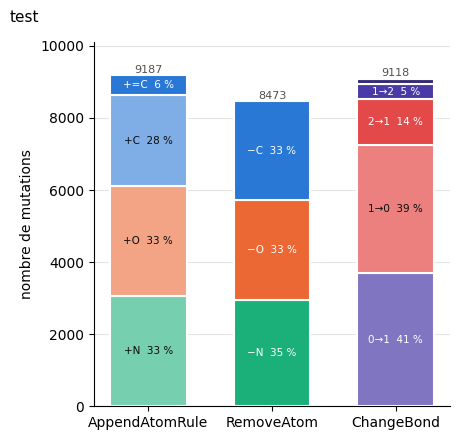

In [24]:
details = nw.mutation_details(OUT_DIR, N_JOBS)       # 
nw.plot_mutation_details({LABEL: details}, save=FIGURES / "05_mutations_detail.png")
plt.show()

## Décompte des atomes et des mutations

,decompte,nom,marche 0,marche 1,marche 2,marche 3,marche 4,marche 5,marche 6,marche 7,...,marche 11,marche 12,marche 13,marche 14,marche 15,marche 16,marche 17,marche 18,marche 19,moyenne
0,atome,C,33566,57524,40531,37982,19458,23712,76722,21017,...,17580,57471,18694,33702,19756,44932,25478,21282,30924,33035.74
1,atome,O,5499,7303,6862,7057,4698,5649,15017,5588,...,3912,12719,5311,7524,5919,8714,5190,6006,6914,6760.21
2,atome,N,16283,23042,18864,17118,9881,11605,49003,9543,...,8911,39687,10863,17135,11775,22642,11859,13427,13416,17375.37
3,atome,S,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.00
4,atome,F,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.00
5,atome,H,31527,38300,33558,34056,20685,24571,61965,21665,...,19971,52393,20365,32827,22353,36924,24079,25687,28268,30236.95
6,mutation (%),SubstituteShiftMG,24.7,24.8,24.35,23.75,25.85,24.15,25.05,22.75,...,24.1,23.55,25.6,23.55,24.4,24.65,24.2,24.9,23.5,24.38
7,mutation (%),AppendAtomRuleMG,23.6,25.25,23.95,24.35,23.4,24.05,26.8,25.05,...,24.35,25.65,22.8,24.15,22.95,25.15,23.4,23.95,24.2,24.18
8,mutation (%),ChangeBondMG,23.8,23.0,23.8,24.2,22.9,24.15,23.15,24.0,...,24.0,24.4,23.65,24.45,25.15,23.4,25.25,24.5,23.55,23.99
9,mutation (%),RemoveAtomMG,22.6,22.0,21.45,22.45,22.6,22.45,20.95,23.2,...,22.85,22.05,22.25,22.05,21.75,22.05,22.55,22.5,23.1,22.30


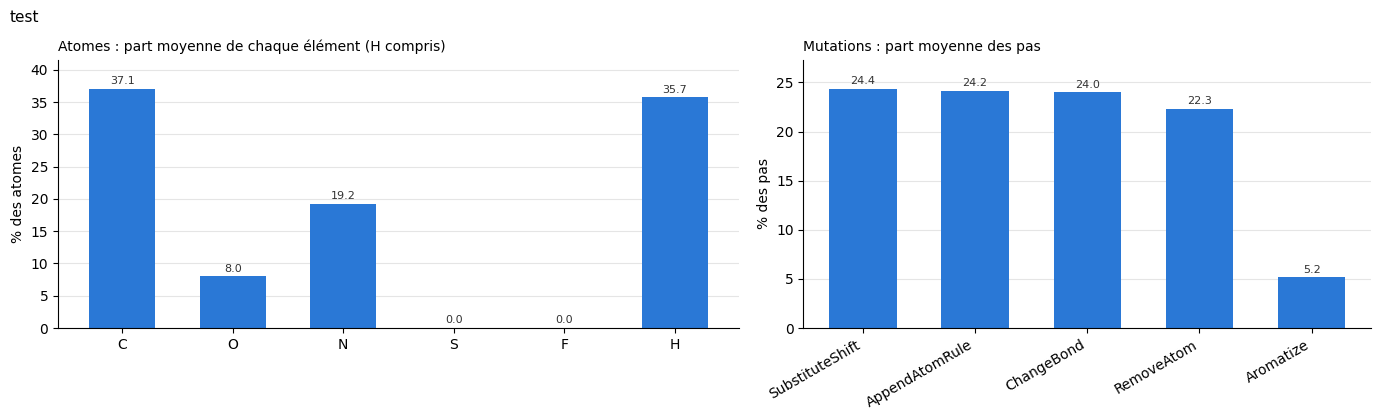

In [25]:
counts = nw.write_counts(OUT_DIR)
display(counts)
nw.plot_counts(counts, save=FIGURES / "04_decompte.png")
plt.show()

## Marches individuelles et moyenne

Un graphe par variable, une courbe par marche (calcul échoué tracé à −2), puis la moyenne ± écart-type.

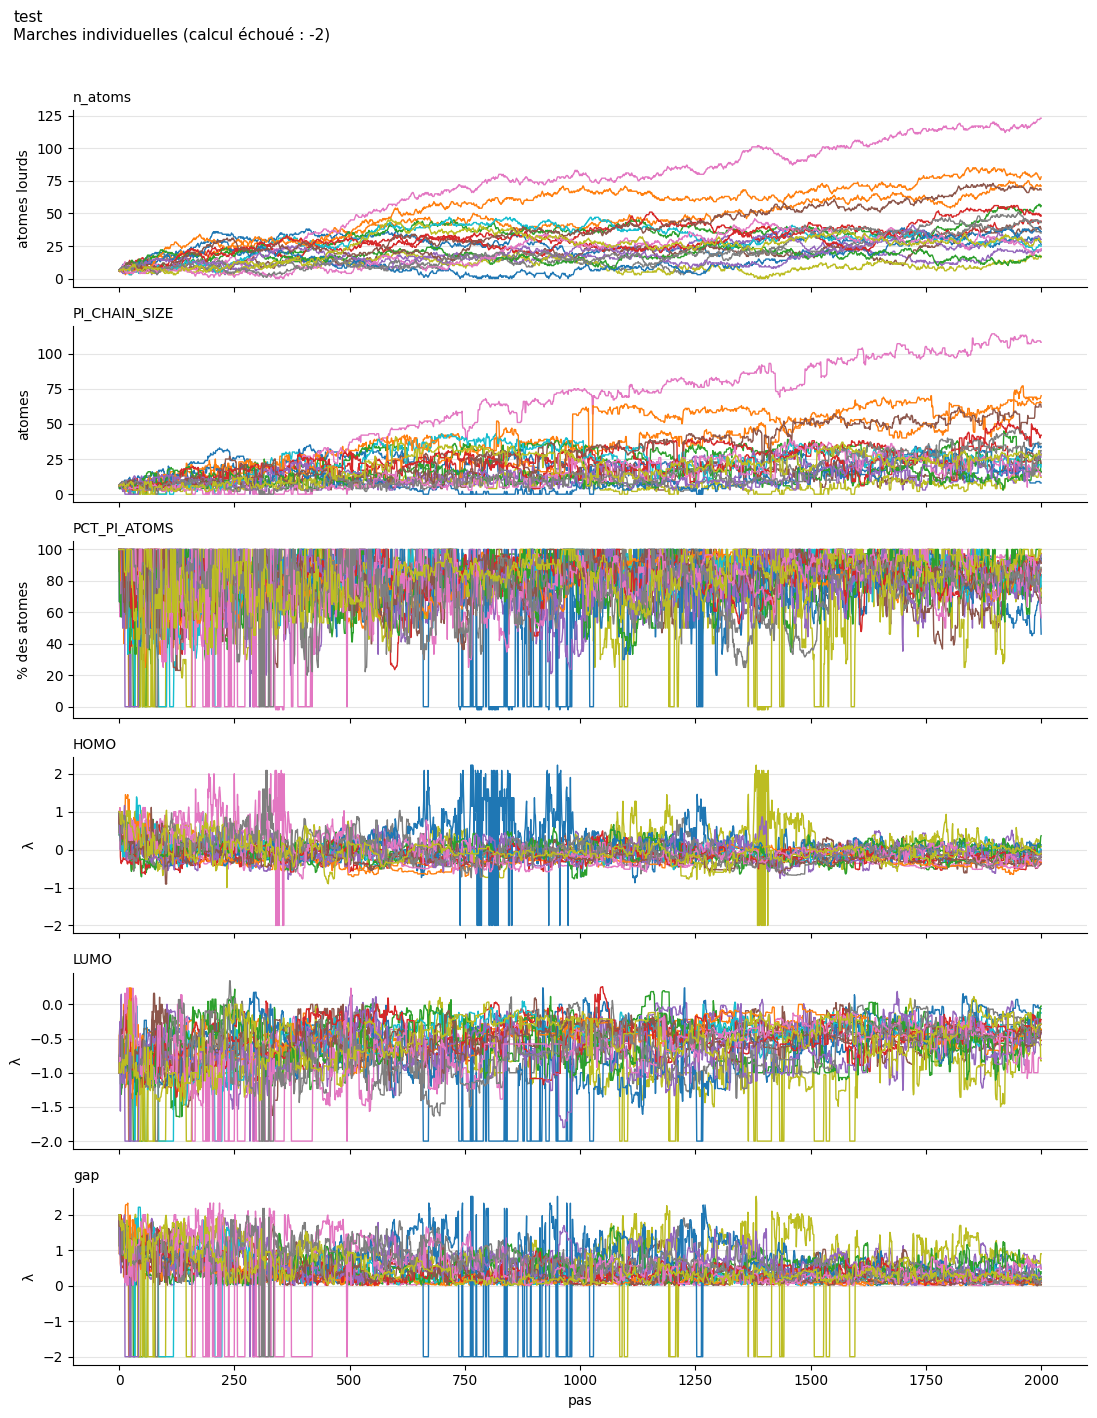

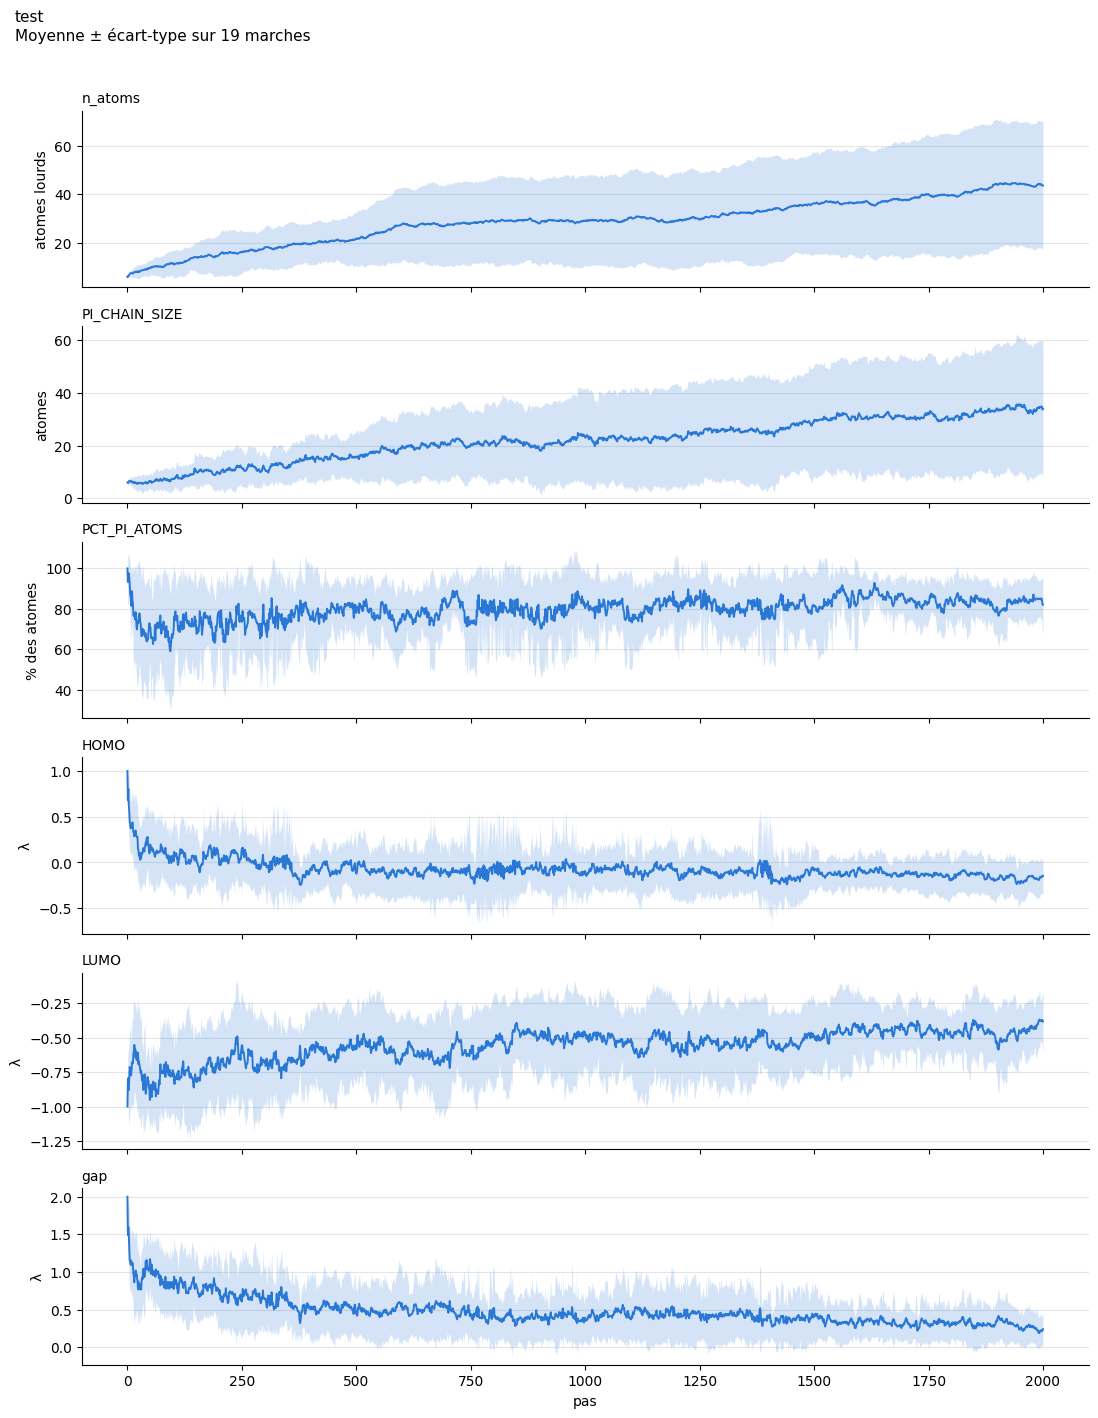

In [26]:
nw.plot_walks(walks, save=FIGURES / "01_marches.png")
plt.show()
nw.plot_mean(walks, save=FIGURES / "03_moyenne.png")
plt.show()

## Longueur d'autocorrélation

ρ(k) : corrélation de Pearson entre la valeur d'une variable à un pas et sa valeur k pas plus loin (voir
`pi_walk.ipynb` pour la définition). Le tableau donne, par variable, la longueur d'autocorrélation
(`figures/02_autocorrelation.png`).

,ℓ marche 0,ℓ marche 1,ℓ marche 2,ℓ marche 3,ℓ marche 4,ℓ marche 5,ℓ marche 6,ℓ marche 7,ℓ marche 9,ℓ marche 10,...,ℓ marche 12,ℓ marche 13,ℓ marche 14,ℓ marche 15,ℓ marche 16,ℓ marche 17,ℓ marche 18,ℓ marche 19,ℓ moyenne,ℓ écart-type
variable,,,,,,,,,,,,,,,,,,,,,
n_atoms,147.552,1050.546,511.724,360.553,225.486,278.657,5181.900,519.376,84.586,481.794,...,1680.096,62.474,508.076,211.776,1385.575,663.858,659.827,413.891,782.591,1146.543
PI_CHAIN_SIZE,25.345,136.398,52.998,55.459,24.726,26.450,1138.374,77.814,17.495,59.023,...,193.375,12.902,54.904,20.728,156.042,55.163,63.033,58.353,120.630,251.163
PCT_PI_ATOMS,11.616,7.779,7.940,16.325,5.563,9.842,9.601,5.350,4.892,14.533,...,19.110,9.888,13.535,9.739,13.899,4.584,6.154,8.209,9.606,4.293
HOMO,14.084,27.622,17.475,14.734,9.125,11.756,29.866,12.545,9.474,12.285,...,32.188,13.889,14.585,9.963,12.913,11.780,12.186,14.253,15.160,6.994
LUMO,16.412,23.588,14.367,34.165,10.567,14.952,21.896,17.354,11.016,20.765,...,12.733,14.829,23.238,10.949,12.832,13.847,19.813,25.117,17.466,6.116
gap,11.141,29.032,11.595,20.144,9.696,12.394,36.723,15.385,11.304,26.023,...,10.002,9.767,15.412,10.745,10.594,17.749,16.055,21.161,16.198,7.476


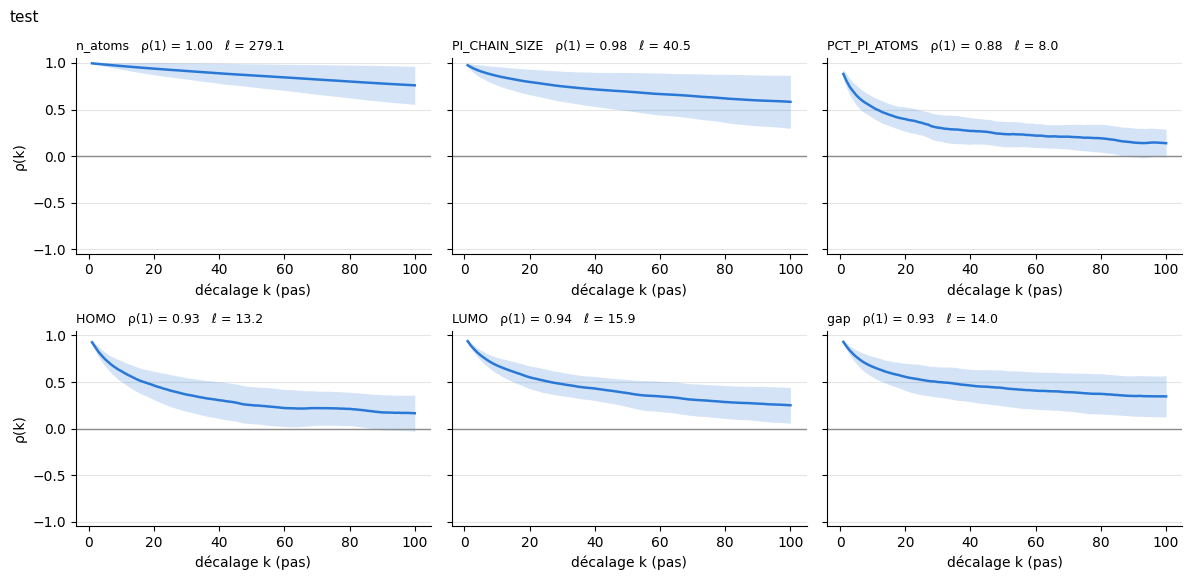

In [27]:
acf, rho = nw.autocorrelation(walks)
display(nw.autocorrelation_summary(acf).round(3))
nw.plot_autocorrelation(rho, nw.VARIABLES, save=FIGURES / "02_autocorrelation.png")
plt.show()

## Variables deux à deux

Chaque variable contre chaque autre, sur tous les pas de toutes les marches : nuage de points et droite de régression
(bande : intervalle de confiance à 95 %), histogramme de chaque variable sur la diagonale. Les calculs échoués sont
exclus paire par paire (`figures/06_paires.png`).

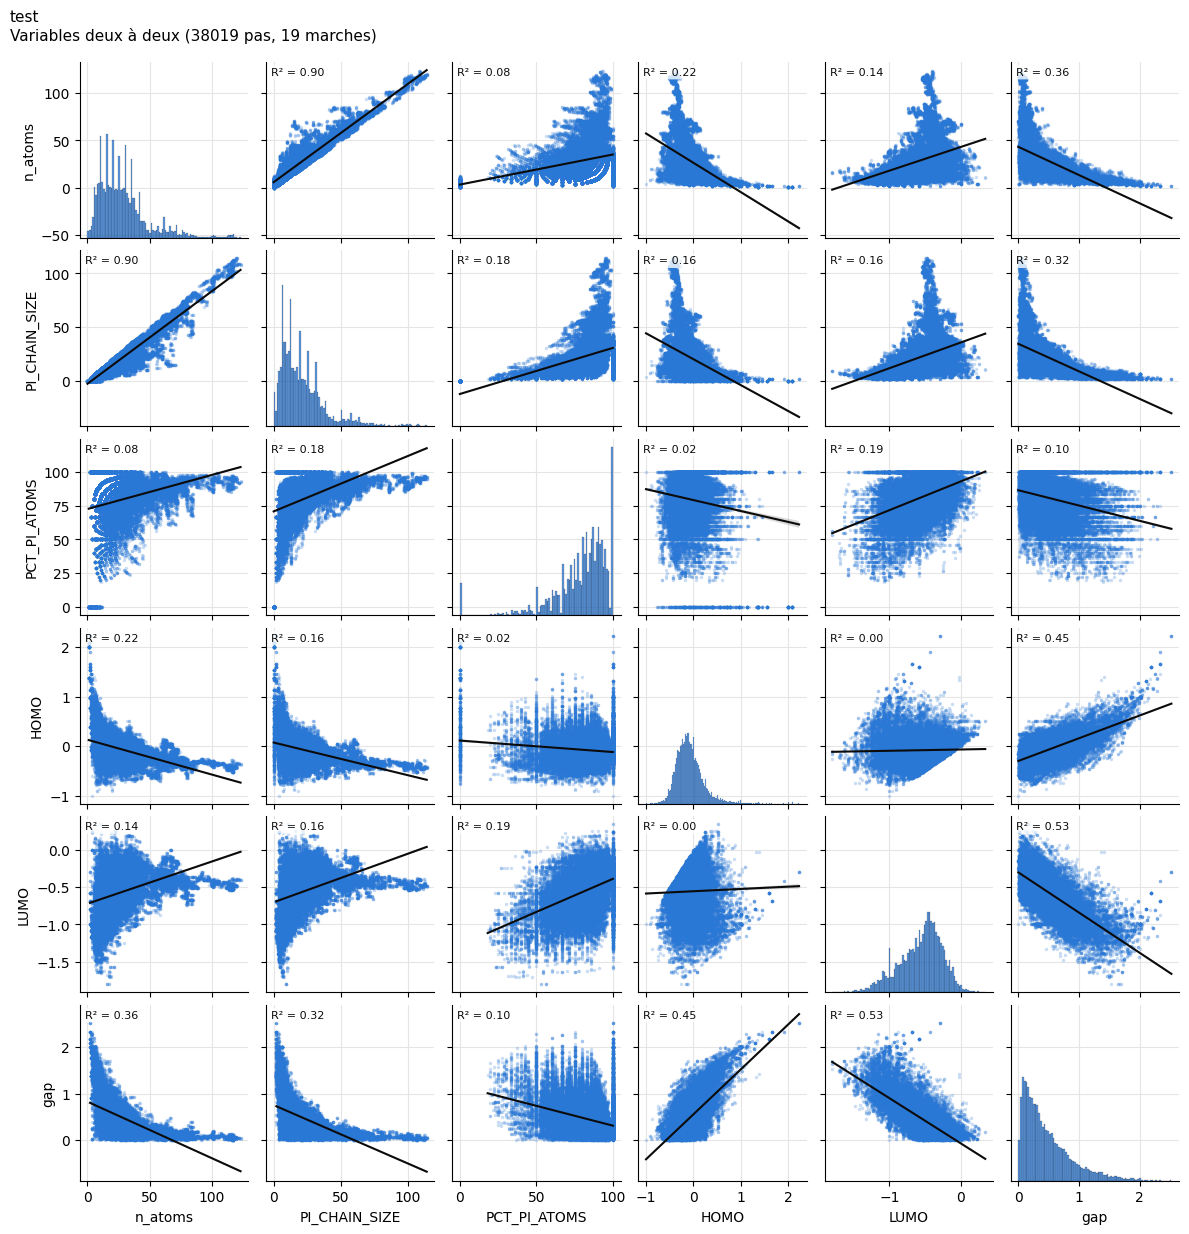

In [28]:
nw.plot_pairs(walks, save=FIGURES / "06_paires.png")
plt.show()

## Parcourir une marche

Molécules de chaque pas, 3 par ligne, avec le type de mutation qui y mène et leurs valeurs.

/Applications/anaconda3/envs/revomol/lib/python3.12/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 100. Change the maxMols value to display more.
  warnings.warn(




In [47]:
WALK = 18                            # numéro de la marche
STEP_START, STEP_STOP = 1300, 1400       # pas affichés (inclus)

nw.show_steps(OUT_DIR, WALK, STEP_START, STEP_STOP)

Nom de l'opération faite à chaque pas, lue en comparant les deux matrices (port de `classify` de l'atelier de
mutations, `evomol/newmut/matrix_diff.py`) : utile quand un type de mutation produit des opérations différentes, ou
pour repérer les pas qui ne changent que l'écriture de Kekulé.

In [30]:
display(nw.walk_operations(OUT_DIR, WALK, STEP_START, STEP_STOP))

,pas,mutation,opération,avant,après
0,1300,SubstituteShiftMG,Substitution O → N sur l'atome 10,C=CC(ON)=C(C=CN)OOC,C=CC(ON)=C(C=CN)ONC
1,1301,RemoveAtomMG,Retrait de N4,C=CC(ON)=C(C=CN)ONC,C=CC(O)=C(C=CN)ONC
2,1302,SubstituteShiftMG,Substitution O → N sur l'atome 3,C=CC(O)=C(C=CN)ONC,C=CC(N)=C(C=CN)ONC
3,1303,SubstituteShiftMG,Substitution N → O sur l'atome 7,C=CC(N)=C(C=CN)ONC,C=CC(N)=C(C=CO)ONC
4,1304,AppendAtomRuleMG,Ajout de O11 sur C5,C=CC(N)=C(C=CO)ONC,C=CC(N)=C(ONC)C(O)=CO
...,...,...,...,...,...
96,1396,SubstituteShiftMG,Substitution N → C sur l'atome 8,C1=NCC1=C1N=CC=N1,C1=CC(=C2C=NC2)N=C1
97,1397,ChangeBondMG,Création de la liaison C4–C6 (ordre 1),C1=CC(=C2C=NC2)N=C1,C1=CC(=C2C3=NC32)N=C1
98,1398,AromatizeMG,Inversion le long du chemin alterné N5–C4–C6,C1=CC(=C2C3=NC32)N=C1,C1=CC(=C2C3=C2N3)N=C1
99,1399,SubstituteShiftMG,Substitution N → O sur l'atome 6,C1=CC(=C2C3=C2N3)N=C1,C1=CC(=C2C3=C2O3)N=C1
